Instead of forcing a neural network to learn the entire solution from scratch, you split the solution into two parts:$$u(x, t) = u_{\text{poly}}(x, t) + g(x, t; \theta)$$Where:$u_{\text{poly}}(x, t)$ (The Baseline / Backbone): A known polynomial expansion (like a Taylor series, Chebyshev polynomials, or a fitted low-order polynomial) that captures the global trend, coarse behavior, or satisfies exact boundary/initial conditions.$g(x, t; \theta)$ (The Neural Network Corrector): A standard neural network parameterized by weights $\theta$ whose job is to learn only the fine-scale residuals, unmodeled nonlinearities, or truncation errors that the polynomial misses.Why This Architecture is Extremely PowerfulHard Boundary Condition Enforcement: You can design $u_{\text{poly}}$ so that it automatically satisfies your boundary or initial conditions (e.g., $u_{\text{poly}}(0) = 1$). By forcing the neural network correction to vanish at the boundaries ($g(0) = 0$), your model respects physical constraints by design, eliminating the need for boundary loss penalties.Easier Optimization for the Neural Network: Neural networks are notoriously biased toward learning low-frequency functions slowly or struggling with strict polynomial scaling over large domains. Providing a polynomial backbone shifts the heavy lifting of global scaling to analytical math, leaving the neural network to focus purely on local high-frequency corrections.Exact Analytical Derivatives: When computing the PDE residual, the derivative of the sum is the sum of the derivatives:$$\frac{\partial u}{\partial x} = \frac{\partial u_{\text{poly}}}{\partial x} + \frac{\partial g}{\partial x}$$Because $u_{\text{poly}}$ is a polynomial, its derivative can often be computed analytically or symbolically with zero numerical error, reducing the burden on automatic differentiation.

In [1]:
import torch
import torch.nn as nn

# 1. Neural Network Corrector g(t)
class CorrectorNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 1)
        )
        
    def forward(self, t):
        return self.net(t)

# 2. Hybrid Model: u(t) = u_poly(t) + g(t)
class HybridPolynomialPINN(nn.Module):
    def __init__(self, corrector_net):
        super().__init__()
        self.corrector = corrector_net
        
    def forward(self, t):
        # Explicit polynomial backbone (e.g., Taylor expansion terms of e^-t: 1 - t + 0.5*t^2)
        u_poly = 1.0 - t + 0.5 * (t ** 2)
        
        # Neural network learns the residual/correction term g(t)
        # Multiplying by (t^2) or similar can optionally enforce hard initial/boundary conditions,
        # but here g(t) directly corrects the polynomial approximation.
        g = self.corrector(t)
        
        return u_poly + g

# Initialize components
corrector = CorrectorNN()
model = HybridPolynomialPINN(corrector)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Collocation points across time domain [0, 1]
t_collocation = torch.linspace(0, 1, 100, requires_grad=True).reshape(-1, 1)

# 3. Training Loop
for epoch in range(1501):
    optimizer.zero_grad()
    
    # Predict total solution u(t)
    u_pred = model(t_collocation)
    
    # Compute first-order time derivative using automatic differentiation
    du_dt = torch.autograd.grad(
        u_pred, t_collocation,
        grad_outputs=torch.ones_like(u_pred),
        create_graph=True
    )[0]
    
    # Governing Differential Equation: du/dt + u = 0
    residual = du_dt + u_pred
    loss = torch.mean(residual ** 2)
    
    loss.backward()
    optimizer.step()
    
    if epoch % 300 == 0:
        print(f"Epoch {epoch:4d} | Residual Loss: {loss.item():.8f}")

print("\nTraining complete! The polynomial backbone handled the baseline trend while the neural network absorbed the correction.")

Epoch    0 | Residual Loss: 0.04491598
Epoch  300 | Residual Loss: 0.00000134
Epoch  600 | Residual Loss: 0.00000127
Epoch  900 | Residual Loss: 0.00000118
Epoch 1200 | Residual Loss: 0.00000109
Epoch 1500 | Residual Loss: 0.00000101

Training complete! The polynomial backbone handled the baseline trend while the neural network absorbed the correction.


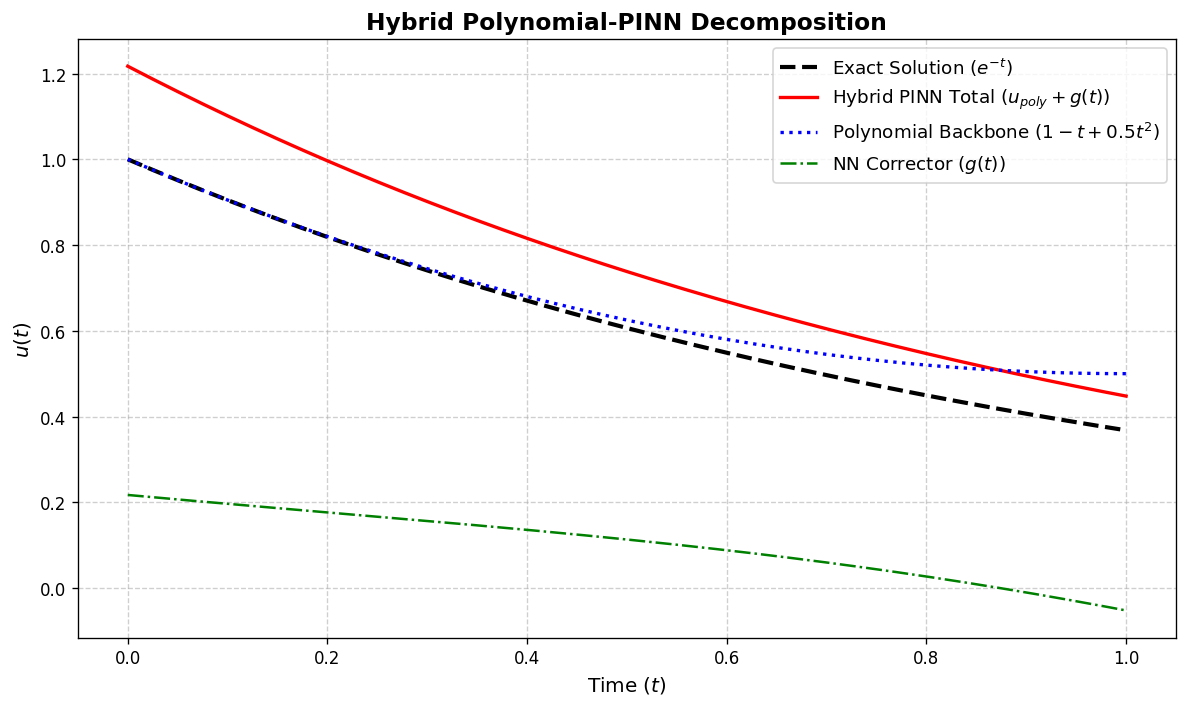

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Define the Hybrid Model (same as before)
class CorrectorNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 1)
        )
    def forward(self, t):
        return self.net(t)

class HybridPolynomialPINN(nn.Module):
    def __init__(self, corrector_net):
        super().__init__()
        self.corrector = corrector_net
    def forward(self, t):
        u_poly = 1.0 - t + 0.5 * (t ** 2)
        g = self.corrector(t)
        return u_poly + g, u_poly, g

# 2. Quick Training
corrector = CorrectorNN()
model = HybridPolynomialPINN(corrector)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

t_collocation = torch.linspace(0, 1, 100, requires_grad=True).reshape(-1, 1)

for epoch in range(1501):
    optimizer.zero_grad()
    u_pred, _, _ = model(t_collocation)
    du_dt = torch.autograd.grad(u_pred, t_collocation, grad_outputs=torch.ones_like(u_pred), create_graph=True)[0]
    residual = du_dt + u_pred
    loss = torch.mean(residual ** 2)
    loss.backward()
    optimizer.step()

# 3. Generate Visualization Data
with torch.no_grad():
    t_test = torch.linspace(0, 1, 200).reshape(-1, 1)
    u_total, u_poly, g_corr = model(t_test)
    u_exact = torch.exp(-t_test) # Analytical solution: e^(-t)

    t_np = t_test.numpy().flatten()
    u_total_np = u_total.numpy().flatten()
    u_poly_np = u_poly.numpy().flatten()
    g_corr_np = g_corr.numpy().flatten()
    u_exact_np = u_exact.numpy().flatten()

# 4. Plotting
plt.figure(figsize=(10, 6), dpi=120)
plt.plot(t_np, u_exact_np, 'k--', label='Exact Solution ($e^{-t}$)', linewidth=2.5)
plt.plot(t_np, u_total_np, 'r-', label='Hybrid PINN Total ($u_{poly} + g(t)$)', linewidth=2)
plt.plot(t_np, u_poly_np, 'b:', label='Polynomial Backbone ($1 - t + 0.5t^2$)', linewidth=2)
plt.plot(t_np, g_corr_np, 'g-.', label='NN Corrector ($g(t)$)', linewidth=1.5)

plt.title('Hybrid Polynomial-PINN Decomposition', fontsize=14, fontweight='bold')
plt.xlabel('Time ($t$)', fontsize=12)
plt.ylabel('$u(t)$', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()